## Preliminaries and definitions

In [1]:
import os
import sys
import re
import json
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

os.environ.setdefault("FLASH_ENV", "remote")


def find_repo_root(start=None):
    start = Path.cwd().resolve() if start is None else Path(start).resolve()
    for path in [start, *start.parents]:
        if (path / "analysis" / "scripts").exists():
            return path

    fallback = Path("/home/mmanresa/glycine26")
    if (fallback / "analysis" / "scripts").exists():
        return fallback

    raise RuntimeError("Could not find repository root containing analysis/scripts")


repo_root = find_repo_root()
scripts_dir = repo_root / "analysis" / "scripts"
if str(scripts_dir) not in sys.path:
    sys.path.insert(0, str(scripts_dir))

import config

AGG_DIR = Path(config.COMBINED_DIR)
CALIB_PATH = (
    Path(config.COMBINED_DIR).parent
    / "Calibrations"
    / "etof_energy_calibration_t0_scan.json"
)

with open(CALIB_PATH, "r", encoding="utf-8") as handle:
    calib = json.load(handle)

best_t0 = calib["t0_tof_units"]
best_slope = calib["slope_eV_tof_unit2"]
best_E0 = calib["E0_eV"]


def tof_to_ke(tof):
    tof = np.asarray(tof, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        ke = best_slope / (tof - best_t0) ** 2 + best_E0
    return np.where(tof > best_t0, ke, np.nan)


plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
})

print("repo_root:", repo_root)
print("combined :", AGG_DIR)
print("calib    :", CALIB_PATH)

repo_root: /home/mmanresa/glycine26
combined : /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined
calib    : /asap3/flash/gpfs/fl24/2026/data/11022188/processed/Calibrations/etof_energy_calibration_t0_scan.json


In [2]:
def keep_mask_like_compute_aggregates_from_h5(handle, trim_start=0, trim_end=0):
    if "between_tdc_files" not in handle:
        return np.ones(handle["gmd"].shape[0], dtype=bool)

    between_tdc_files = handle["between_tdc_files"][:].astype(bool)
    good_positions = np.where(~between_tdc_files)[0]

    if trim_end > 0:
        good_positions = good_positions[trim_start:-trim_end]
    else:
        good_positions = good_positions[trim_start:]

    keep = np.zeros(between_tdc_files.shape[0], dtype=bool)
    keep[good_positions] = True
    return keep


def delay_window_to_stage_window(delay_window_fs):
    if delay_window_fs is None:
        return None

    lo_fs, hi_fs = delay_window_fs
    lo_stage = lo_fs / FS_PER_STAGE_UNIT + DELAY_ZERO_STAGE
    hi_stage = hi_fs / FS_PER_STAGE_UNIT + DELAY_ZERO_STAGE

    return min(lo_stage, hi_stage), max(lo_stage, hi_stage)


def read_bunch_position_diagnostics(
    source_h5,
    ke_ranges,
    gmd_ranges,
    *,
    delay_window_fs=None,
    trim_start=0,
    trim_end=0,
    chunk_trains=1000,
):
    source_h5 = Path(source_h5)
    ke_ranges = [tuple(r) for r in ke_ranges]
    gmd_ranges = {name: tuple(value) for name, value in gmd_ranges.items()}
    delay_window_stage = delay_window_to_stage_window(delay_window_fs)

    with h5py.File(source_h5, "r") as handle:
        keep = keep_mask_like_compute_aggregates_from_h5(
            handle,
            trim_start=trim_start,
            trim_end=trim_end,
        )

        n_trains, n_bunch = handle["gmd"].shape
        max_slots = handle["tofs_e"].shape[-1]
        bunch = np.arange(n_bunch)

        gmd_kept = handle["gmd"][:][keep]

        if delay_window_stage is not None:
            if "z" not in handle:
                raise KeyError("Requested DELAY_WINDOW_FS, but source H5 has no /z dataset.")

            z_kept = handle["z"][:][keep]
            z_lo, z_hi = delay_window_stage
            delay_kept = np.isfinite(z_kept) & (z_kept >= z_lo) & (z_kept < z_hi)
            gmd_for_distribution = np.where(delay_kept, gmd_kept, np.nan)
        else:
            gmd_for_distribution = gmd_kept

        out = {
            "bunch": bunch,
            "gmd_kept": gmd_for_distribution,
            "max_slots": max_slots,
            "ke_ranges": ke_ranges,
            "gmd_ranges": gmd_ranges,
            "delay_window_fs": delay_window_fs,
            "stats": {},
        }

        for gmd_label in gmd_ranges:
            out["stats"][gmd_label] = {}
            for ke_range in ke_ranges:
                out["stats"][gmd_label][ke_range] = {
                    "shots": np.zeros(n_bunch, dtype=np.int64),
                    "sum_gmd": np.zeros(n_bunch, dtype=np.float64),
                    "electrons": np.zeros(n_bunch, dtype=np.float64),
                    "slot_filled": np.zeros(n_bunch, dtype=np.int64),
                }

        for start in range(0, n_trains, chunk_trains):
            stop = min(start + chunk_trains, n_trains)
            row_keep = keep[start:stop]
            if not row_keep.any():
                continue

            gmd = handle["gmd"][start:stop][row_keep]
            tofs = handle["tofs_e"][start:stop][row_keep]

            selected_by_delay = np.ones_like(gmd, dtype=bool)
            if delay_window_stage is not None:
                z = handle["z"][start:stop][row_keep]
                z_lo, z_hi = delay_window_stage
                selected_by_delay = np.isfinite(z) & (z >= z_lo) & (z < z_hi)

            finite_gmd = np.isfinite(gmd)
            valid_hit = tofs > 0
            hit_ke = tof_to_ke(tofs)
            slot_filled = np.count_nonzero(valid_hit, axis=-1) >= max_slots

            counts_by_ke = {}
            for ke_min, ke_max in ke_ranges:
                hit_selected = valid_hit & np.isfinite(hit_ke)
                hit_selected &= hit_ke >= ke_min
                hit_selected &= hit_ke < ke_max
                counts_by_ke[(ke_min, ke_max)] = np.count_nonzero(hit_selected, axis=-1)

            for gmd_label, gmd_range in gmd_ranges.items():
                gmd_lo, gmd_hi = gmd_range
                shot_selected = finite_gmd & selected_by_delay

                if gmd_lo is not None:
                    shot_selected &= gmd >= gmd_lo
                if gmd_hi is not None:
                    shot_selected &= gmd < gmd_hi

                for ke_range in ke_ranges:
                    stats = out["stats"][gmd_label][ke_range]
                    counts = counts_by_ke[ke_range]

                    stats["shots"] += np.count_nonzero(shot_selected, axis=0)
                    stats["sum_gmd"] += np.nansum(np.where(shot_selected, gmd, 0.0), axis=0)
                    stats["electrons"] += np.nansum(np.where(shot_selected, counts, 0.0), axis=0)
                    stats["slot_filled"] += np.count_nonzero(shot_selected & slot_filled, axis=0)

        for gmd_label in gmd_ranges:
            for ke_range in ke_ranges:
                stats = out["stats"][gmd_label][ke_range]
                with np.errstate(invalid="ignore", divide="ignore"):
                    stats["mean_gmd"] = stats["sum_gmd"] / stats["shots"]
                    stats["electrons_per_shot"] = stats["electrons"] / stats["shots"]
                    stats["electrons_per_gmd"] = stats["electrons"] / stats["sum_gmd"]
                    stats["slot_filled_frac"] = stats["slot_filled"] / stats["shots"]

    return out


# --- Helper: reproduce the same train-selection mask used above ---

def _keep_mask_for_bunch_checks(f, trim_start=0, trim_end=0):
    if "between_tdc_files" not in f:
        return np.ones(f["gmd"].shape[0], dtype=bool)

    btf = f["between_tdc_files"][:].astype(bool)
    good_pos = np.where(~btf)[0]

    if trim_end > 0:
        good_pos = good_pos[trim_start:-trim_end]
    else:
        good_pos = good_pos[trim_start:]

    keep = np.zeros(btf.shape[0], dtype=bool)
    keep[good_pos] = True

    return keep
    


## Loading data

In [30]:
# --- Bunch-position diagnostic configuration ---

# Exact aggregate file to analyse. Change this line to select a different dataset/photon energy.
AGG_FILENAME = "glycine_delay_scan_150C_274.0eV_aggregates_tr_etof1.h5"

# Delay selection for time-resolved scans.
# None = combine all delays; otherwise use a window in fs, e.g. (-5, 1.5).
DELAY_ZERO_STAGE = 0.0
FS_PER_STAGE_UNIT = 3.33 / 10000.0
DELAY_WINDOW_FS = None

# Fixed GMD bands used for bunch-position comparisons.
BUNCH_GMD_RANGES = {
    "1-2 uJ": (1.0, 2.0),
    "3-4 uJ": (3.0, 4.0),
    "5-6 uJ": (5.0, 6.0),
    "6-8 uJ": (6.0, 8.0),
    "8-12 uJ": (8.0, 12.0),
}

# Electron kinetic-energy ranges.
KE_RANGES = [
    (180, 280),
    (190, 220),
]

CHUNK_TRAINS = 1000
MIN_SHOTS_PER_BUNCH = 50

In [31]:
# --- Aggregate metadata loader ---

def load_aggregate_info(path):
    path = Path(path)
    with h5py.File(path, "r") as handle:
        metadata = {}
        for key in handle.attrs:
            value = handle.attrs[key]
            if isinstance(value, bytes):
                value = value.decode()
            elif isinstance(value, np.ndarray):
                value = value.tolist()
            metadata[key] = value

        info = {
            "path": path,
            "metadata": metadata,
            "tof_edges": handle["tof_edges"][:],
            "gmd_edges": handle["gmd_edges"][:],
            "n_per_bin": handle["n_per_bin"][:],
            "G": handle["G"][:],
            "D_shape": handle["D"].shape if "D" in handle else None,
            "z_edges": handle["z_edges"][:] if "z_edges" in handle else None,
        }

    return info

In [32]:
# --- Load selected aggregate and recover its source H5 ---

diag_path = AGG_DIR / AGG_FILENAME

if not diag_path.exists():
    raise FileNotFoundError(f"Aggregate file not found:\n{diag_path}")

diag_agg = load_aggregate_info(diag_path)

input_h5 = diag_agg["metadata"].get("input_h5", "")
if isinstance(input_h5, bytes):
    input_h5 = input_h5.decode()
source_h5 = Path(input_h5)

if not source_h5.exists():
    raise FileNotFoundError(f"Source H5 does not exist:\n{source_h5}")

TRIM_START = int(diag_agg["metadata"].get("trim_start", 0))
TRIM_END = int(diag_agg["metadata"].get("trim_end", 0))

if diag_agg["z_edges"] is None:
    if DELAY_WINDOW_FS is not None:
        raise ValueError("A delay window was requested, but this aggregate has no z/delay axis.")
    delay_selection_label = "all shots, no delay axis"
else:
    z_edges = np.asarray(diag_agg["z_edges"], dtype=float)
    delay_edges_fs = (z_edges - DELAY_ZERO_STAGE) * FS_PER_STAGE_UNIT
    delay_centres_fs = 0.5 * (delay_edges_fs[:-1] + delay_edges_fs[1:])
    delay_selection_label = "all delays" if DELAY_WINDOW_FS is None else f"delay {DELAY_WINDOW_FS[0]} to {DELAY_WINDOW_FS[1]} fs"

print("Diagnostic aggregate:", diag_path)
print("Source H5:", source_h5)
print("Delay selection:", delay_selection_label)
print("trim_start, trim_end:", TRIM_START, TRIM_END)

with h5py.File(source_h5, "r") as handle:
    print("\ngmd shape:", handle["gmd"].shape)
    print("tofs_e shape:", handle["tofs_e"].shape)
    print("max eTOF hit slots:", handle["tofs_e"].shape[-1])
    print("z shape:", handle["z"].shape if "z" in handle else "no /z dataset")

print("\naggregate D shape:", diag_agg["D_shape"])
print("aggregate GMD edges:", diag_agg["gmd_edges"])

if diag_agg["z_edges"] is not None:
    print("aggregate z bins:", len(diag_agg["z_edges"]) - 1)
    print("delay range fs:", np.nanmin(delay_edges_fs), "to", np.nanmax(delay_edges_fs))

Diagnostic aggregate: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_274.0eV_aggregates_tr_etof1.h5
Source H5: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_274.0eV.h5
Delay selection: all delays
trim_start, trim_end: 3 3

gmd shape: (33711, 101)
tofs_e shape: (33711, 101, 50)
max eTOF hit slots: 50
z shape: (33711, 101)

aggregate D shape: (4, 53, 5000)
aggregate GMD edges: [ 0.  3.  6. 12. 24.]
aggregate z bins: 53
delay range fs: -4.995 to 30.303


In [33]:
# --- Build bunch-position diagnostics ---

bunch_diag = read_bunch_position_diagnostics(
    source_h5,
    KE_RANGES,
    {"all": (None, None), **BUNCH_GMD_RANGES},
    delay_window_fs=DELAY_WINDOW_FS,
    trim_start=TRIM_START,
    trim_end=TRIM_END,
    chunk_trains=CHUNK_TRAINS,
)

bunch = bunch_diag["bunch"]

print("Loaded bunch diagnostic")
print("  aggregate:", diag_path.name)
print("  source H5:", source_h5.name)
print("  GMD kept shape:", bunch_diag["gmd_kept"].shape)
print("  bunch slots:", bunch.size)
print("  selected shots:", np.count_nonzero(np.isfinite(bunch_diag["gmd_kept"])))
print("  selection:", delay_selection_label)
print("  GMD ranges:")
for label, gmd_range in bunch_diag["gmd_ranges"].items():
    print(f"    {label}: {gmd_range}")

Loaded bunch diagnostic
  aggregate: glycine_delay_scan_150C_274.0eV_aggregates_tr_etof1.h5
  source H5: glycine_delay_scan_150C_274.0eV.h5
  GMD kept shape: (32788, 101)
  bunch slots: 101
  selected shots: 3307144
  selection: all delays
  GMD ranges:
    all: (None, None)
    1-2 uJ: (1.0, 2.0)
    3-4 uJ: (3.0, 4.0)
    5-6 uJ: (5.0, 6.0)
    6-8 uJ: (6.0, 8.0)
    8-12 uJ: (8.0, 12.0)


## Preliminary investigations

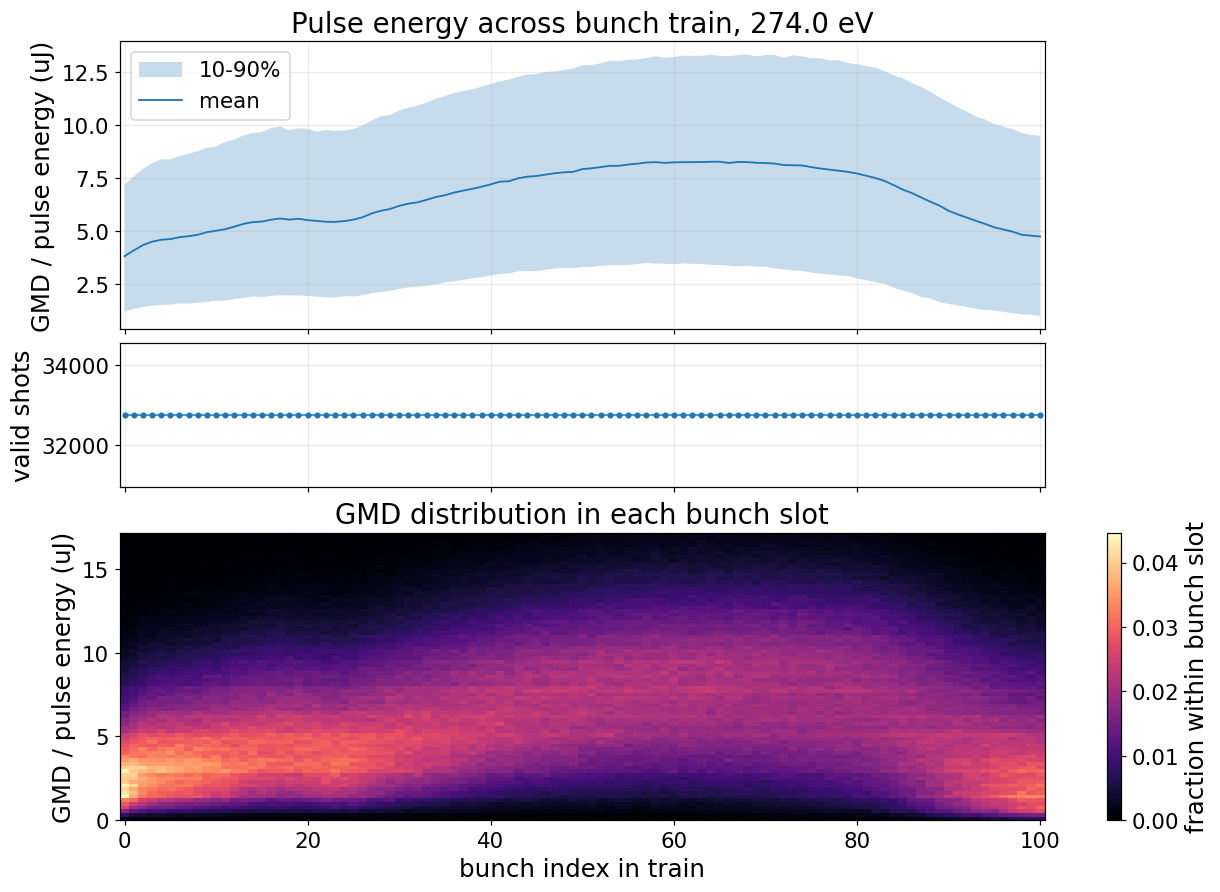

In [34]:
# Photon energy of the currently loaded dataset, taken from its filename.
PLOT_PHOTON_ENERGY_EV = float(diag_path.name.split("eV")[0].split("_")[-1])

bunch = bunch_diag["bunch"]
gmd_kept = bunch_diag["gmd_kept"]

gmd_q10, gmd_med, gmd_q90 = np.nanpercentile(gmd_kept, [10, 50, 90], axis=0)
gmd_mean = np.nanmean(gmd_kept, axis=0)
valid_gmd_shots = np.count_nonzero(np.isfinite(gmd_kept), axis=0)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(11, 8),
    sharex=True,
    constrained_layout=True,
    gridspec_kw={"height_ratios": [2.0, 1.0, 2.0]},
)

axes[0].fill_between(bunch, gmd_q10, gmd_q90, alpha=0.25, label="10-90%")
axes[0].plot(bunch, gmd_mean, lw=1.2, label="mean")
axes[0].set_ylabel("GMD / pulse energy (uJ)")
axes[0].set_title(f"Pulse energy across bunch train, {PLOT_PHOTON_ENERGY_EV:.1f} eV")
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].plot(bunch, valid_gmd_shots, "o-", ms=3, lw=1.0)
axes[1].set_ylabel("valid shots")
axes[1].grid(alpha=0.25)

gmd_hi_plot = np.nanpercentile(gmd_kept, 99.5)
gmd_edges_plot = np.linspace(0.0, gmd_hi_plot, 80)

H, bunch_edges, gmd_edges = np.histogram2d(
    np.tile(bunch, gmd_kept.shape[0]),
    gmd_kept.ravel(),
    bins=[np.arange(bunch.size + 1) - 0.5, gmd_edges_plot],
)

with np.errstate(invalid="ignore", divide="ignore"):
    H_frac = H / np.maximum(H.sum(axis=1, keepdims=True), 1)

im = axes[2].pcolormesh(
    bunch_edges,
    gmd_edges,
    H_frac.T,
    shading="auto",
    cmap="magma",
)
axes[2].set_xlabel("bunch index in train")
axes[2].set_ylabel("GMD / pulse energy (uJ)")
axes[2].set_title("GMD distribution in each bunch slot")
fig.colorbar(im, ax=axes[2], label="fraction within bunch slot")

plt.show()

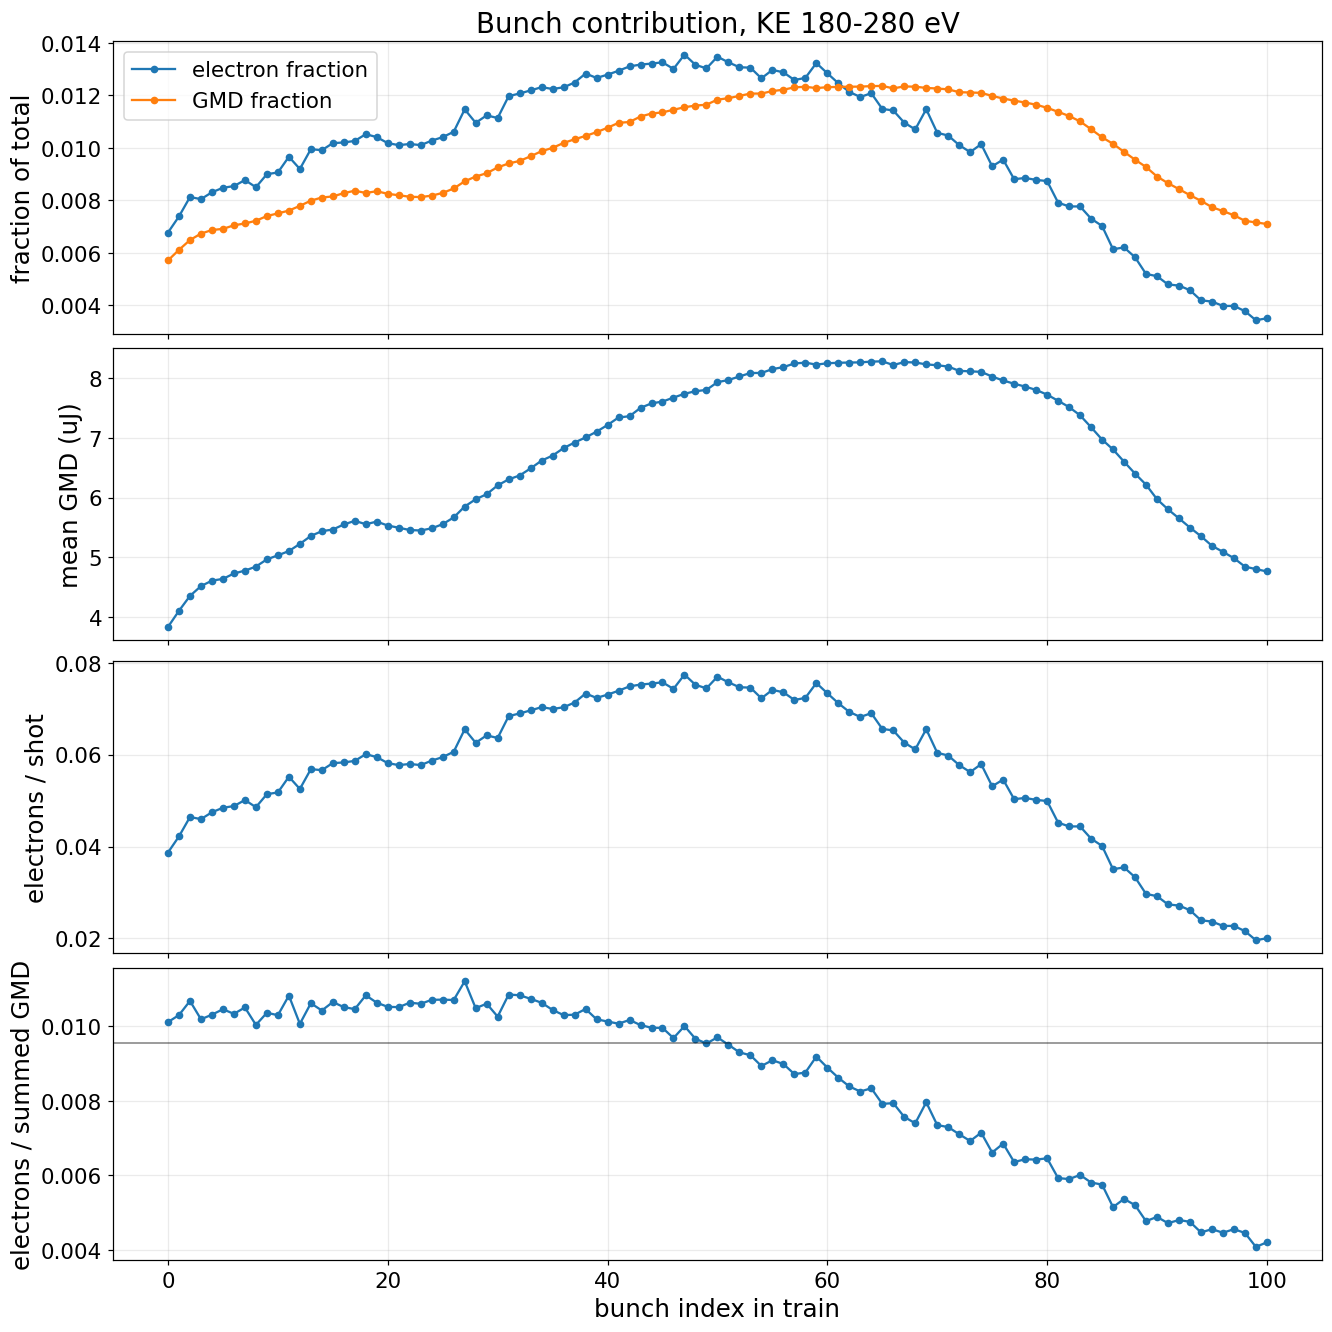

KE 180-280 eV
  total electrons: 187068
  total summed GMD: 2.19549e+07 uJ
  median electrons/GMD over bunch slots: 0.00953363


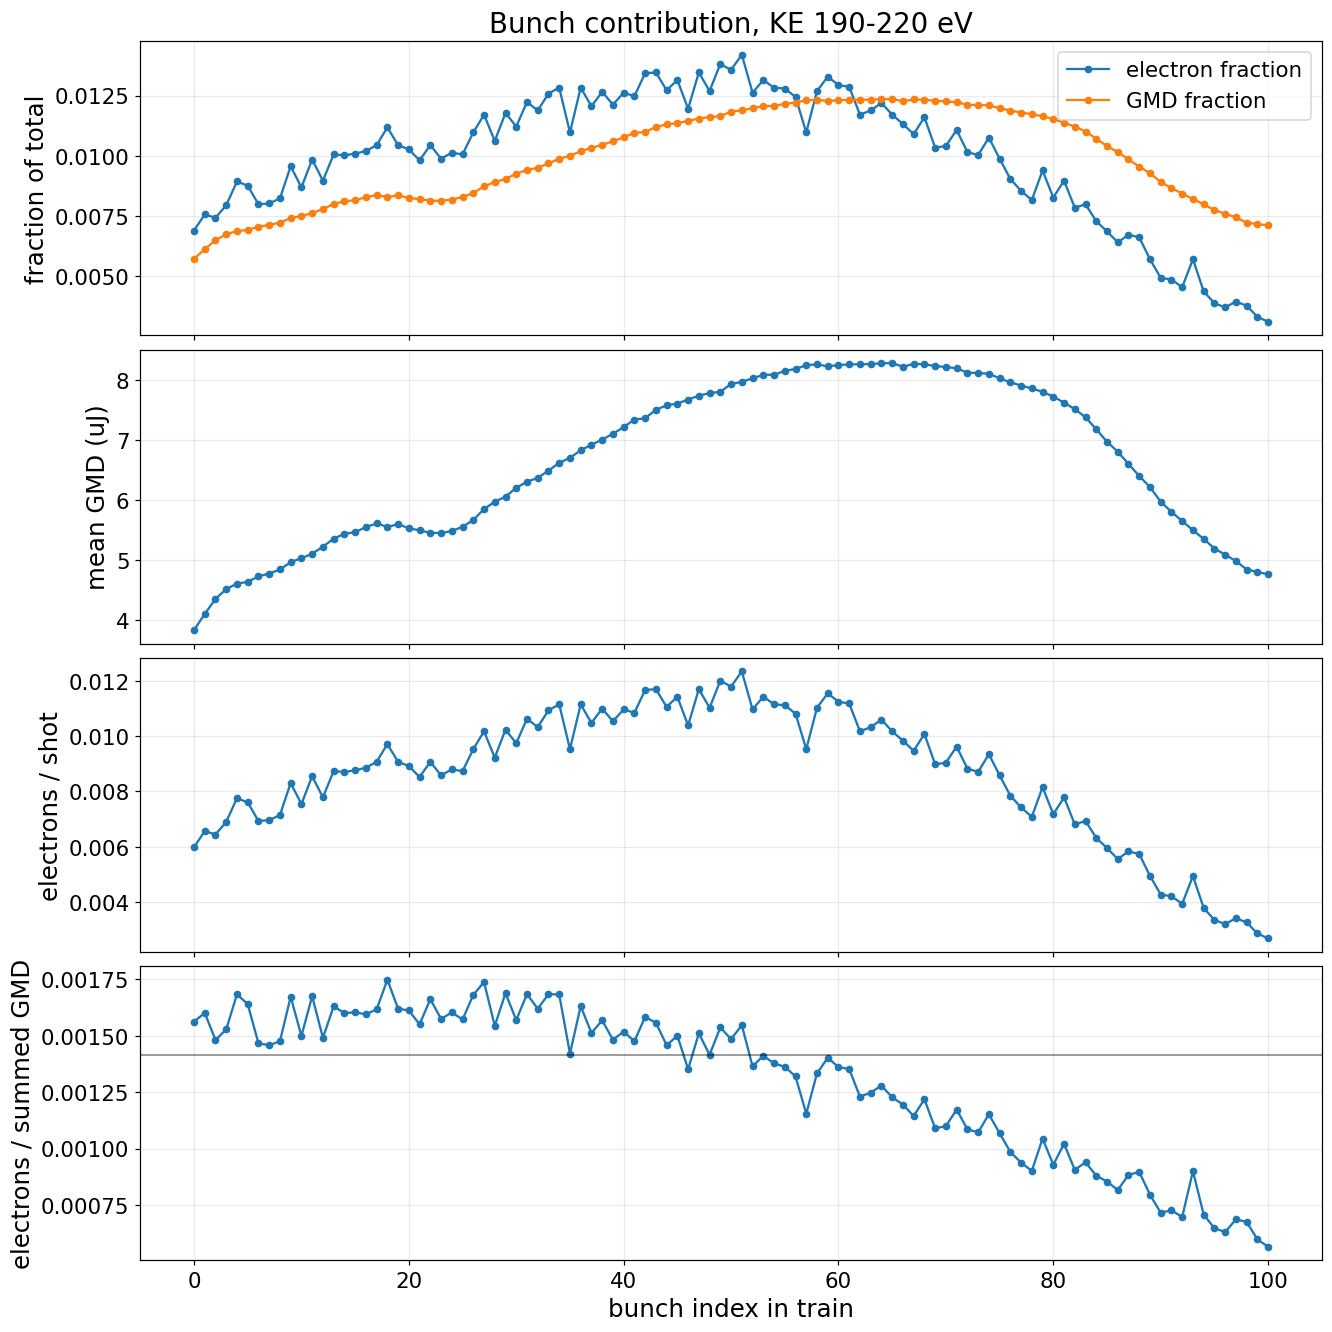

KE 190-220 eV
  total electrons: 28447
  total summed GMD: 2.19549e+07 uJ
  median electrons/GMD over bunch slots: 0.00141623


In [35]:
# Set global font sizes before the loop
plt.rcParams.update({
    'font.size': 14,          # Global default font size
    'axes.labelsize': 16,     # Axis x and y labels
    'axes.titlesize': 18,     # Subplot title
    'xtick.labelsize': 14,    # X-axis tick labels
    'ytick.labelsize': 14,    # Y-axis tick labels
    'legend.fontsize': 14     # Legend font size
})

for ke_range in KE_RANGES:
    stats = bunch_diag["stats"]["all"][ke_range]
    good = stats["shots"] >= MIN_SHOTS_PER_BUNCH

    total_electrons = np.nansum(stats["electrons"])
    total_gmd = np.nansum(stats["sum_gmd"])

    electron_fraction = stats["electrons"] / total_electrons
    gmd_fraction = stats["sum_gmd"] / total_gmd

    # Slightly increased figure size to accommodate larger text cleanly
    fig, axes = plt.subplots(
        4,
        1,
        figsize=(12, 12),
        sharex=True,
        constrained_layout=True,
    )

    # Fraction of the total electron signal and total GMD
    axes[0].plot(
        bunch[good],
        electron_fraction[good],
        "o-",
        ms=4,
        lw=1.5,
        label="electron fraction",
    )
    axes[0].plot(
        bunch[good],
        gmd_fraction[good],
        "o-",
        ms=4,
        lw=1.5,
        label="GMD fraction",
    )
    axes[0].set_ylabel("fraction of total")
    axes[0].set_title(f"Bunch contribution, KE {ke_range[0]}-{ke_range[1]} eV")
    axes[0].grid(alpha=0.25)
    axes[0].legend()

    # Mean FEL pulse energy at each bunch position
    axes[1].plot(
        bunch[good],
        stats["mean_gmd"][good],
        "o-",
        ms=4,
        lw=1.5,
    )
    axes[1].set_ylabel("mean GMD (uJ)")
    axes[1].grid(alpha=0.25)

    # Mean number of detected electrons per shot
    axes[2].plot(
        bunch[good],
        stats["electrons_per_shot"][good],
        "o-",
        ms=4,
        lw=1.5,
    )
    axes[2].set_ylabel("electrons / shot")
    axes[2].grid(alpha=0.25)

    # Electron yield normalised by the summed GMD
    axes[3].plot(
        bunch[good],
        stats["electrons_per_gmd"][good],
        "o-",
        ms=4,
        lw=1.5,
    )
    axes[3].axhline(
        np.nanmedian(stats["electrons_per_gmd"][good]),
        color="k",
        lw=1.0,
        alpha=0.5,
    )
    axes[3].set_xlabel("bunch index in train")
    axes[3].set_ylabel("electrons / summed GMD")
    axes[3].grid(alpha=0.25)

    # Ensure tick marks and tick label sizes are applied across all axes
    for ax in axes:
        ax.tick_params(axis='both', which='major', labelsize=14)

    plt.show()

    print(f"KE {ke_range[0]}-{ke_range[1]} eV")
    print(f"  total electrons: {total_electrons:.6g}")
    print(f"  total summed GMD: {total_gmd:.6g} uJ")
    print(
        "  median electrons/GMD over bunch slots: "
        f"{np.nanmedian(stats['electrons_per_gmd'][good]):.6g}"
    )


KE 180-280 eV
      1-2 uJ (1.0, 2.0): overall e/GMD = 0.00885862
      3-4 uJ (3.0, 4.0): overall e/GMD = 0.0092662
      5-6 uJ (5.0, 6.0): overall e/GMD = 0.0091548
      6-8 uJ (6.0, 8.0): overall e/GMD = 0.00905713
     8-12 uJ (8.0, 12.0): overall e/GMD = 0.00834968


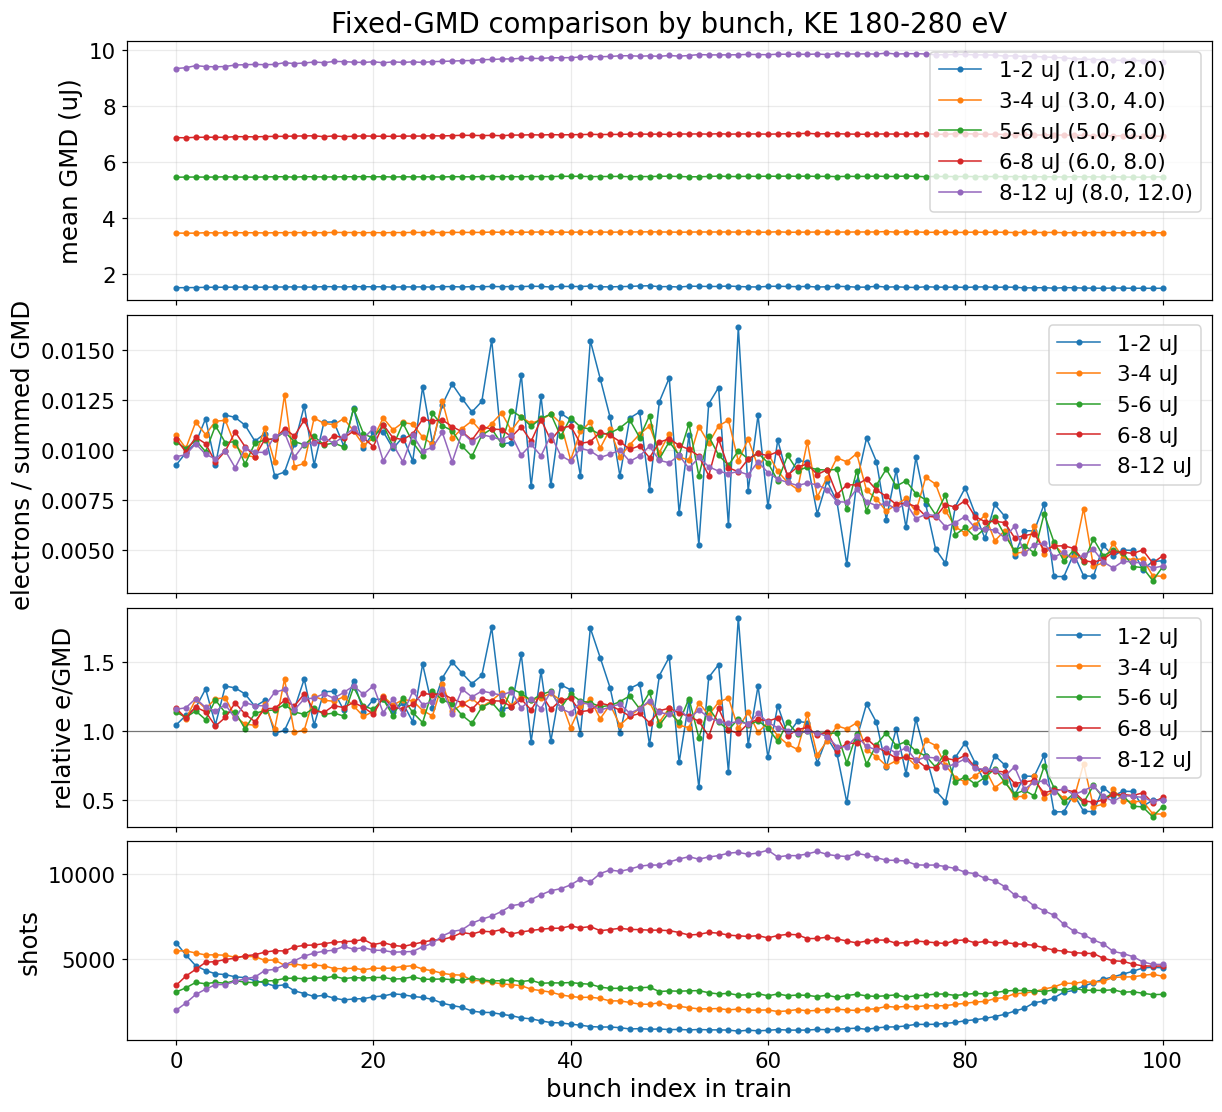


KE 190-220 eV
      1-2 uJ (1.0, 2.0): overall e/GMD = 0.00132683
      3-4 uJ (3.0, 4.0): overall e/GMD = 0.00138065
      5-6 uJ (5.0, 6.0): overall e/GMD = 0.00142653
      6-8 uJ (6.0, 8.0): overall e/GMD = 0.00137498
     8-12 uJ (8.0, 12.0): overall e/GMD = 0.00126931


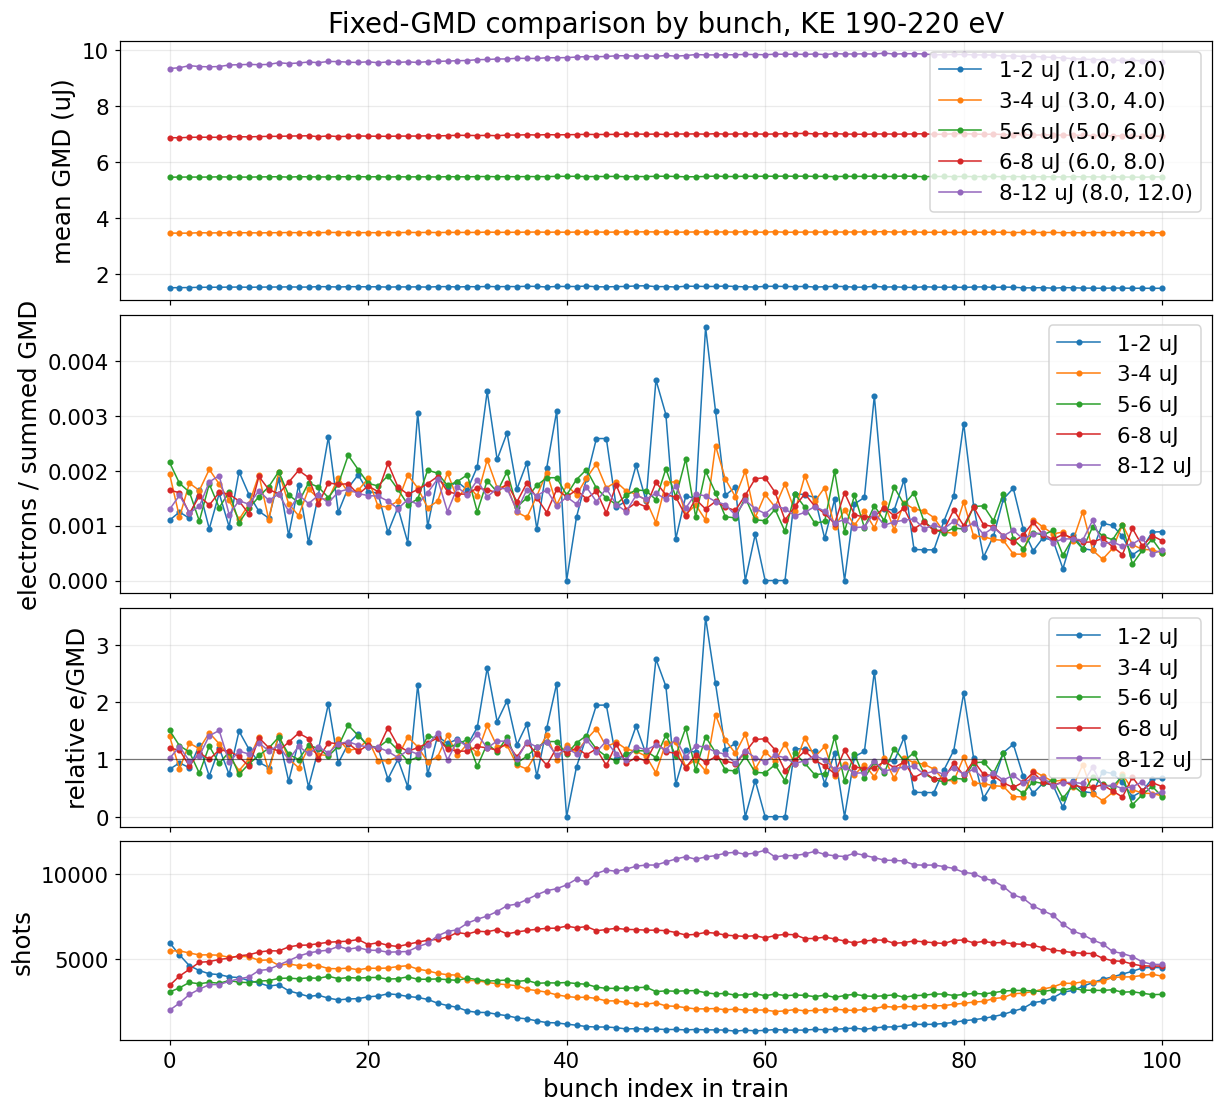

In [36]:
# --- Fixed-GMD comparison as a function of bunch position ---

GMD_LABELS = [label for label in bunch_diag["gmd_ranges"] if label != "all"]

for ke_range in KE_RANGES:
    fig, axes = plt.subplots(4, 1, figsize=(11, 10), sharex=True, constrained_layout=True, gridspec_kw={"height_ratios": [1.3, 1.4, 1.1, 1.0]})

    print(f"\nKE {ke_range[0]}-{ke_range[1]} eV")

    for label in GMD_LABELS:
        st = bunch_diag["stats"][label][ke_range]
        good = (st["shots"] >= MIN_SHOTS_PER_BUNCH) & np.isfinite(st["mean_gmd"]) & np.isfinite(st["electrons_per_gmd"])

        overall_e_gmd = np.nansum(st["electrons"][good]) / np.nansum(st["sum_gmd"][good])
        relative_e_gmd = st["electrons_per_gmd"] / overall_e_gmd
        gmd_range = bunch_diag["gmd_ranges"][label]

        axes[0].plot(bunch[good], st["mean_gmd"][good], "o-", ms=3, lw=1.0, label=f"{label} {gmd_range}")
        axes[1].plot(bunch[good], st["electrons_per_gmd"][good], "o-", ms=3, lw=1.0, label=label)
        axes[2].plot(bunch[good], relative_e_gmd[good], "o-", ms=3, lw=1.0, label=label)
        axes[3].plot(bunch[good], st["shots"][good], "o-", ms=3, lw=1.0, label=label)

        print(f"  {label:>10s} {gmd_range}: overall e/GMD = {overall_e_gmd:.6g}")

    axes[0].set_ylabel("mean GMD (uJ)")
    axes[0].set_title(f"Fixed-GMD comparison by bunch, KE {ke_range[0]}-{ke_range[1]} eV")
    axes[0].grid(alpha=0.25)
    axes[0].legend()

    axes[1].set_ylabel("electrons / summed GMD")
    axes[1].grid(alpha=0.25)
    axes[1].legend()

    #Dividing the counts/gmd at each bunch index by the counts/gmd over the whole bunch for that gmd bin
    # axes[2].axhline(1.0, color="k", lw=0.8, alpha=0.5)
    # axes[2].set_ylabel("relative e/GMD")
    # axes[2].grid(alpha=0.25)
    # axes[2].legend()

    axes[3].set_xlabel("bunch index in train")
    axes[3].set_ylabel("shots")
    axes[3].grid(alpha=0.25)
    # axes[3].legend()

    plt.show()

In [37]:
# --- Largest bunch-slot deviations from each fixed-GMD band's overall response ---

SUMMARY_KE_RANGE = KE_RANGES[0]
GMD_LABELS = [label for label in bunch_diag["gmd_ranges"] if label != "all"]

print(f"Summary KE range: {SUMMARY_KE_RANGE[0]}-{SUMMARY_KE_RANGE[1]} eV")

for label in GMD_LABELS:
    st = bunch_diag["stats"][label][SUMMARY_KE_RANGE]
    good = (st["shots"] >= MIN_SHOTS_PER_BUNCH) & np.isfinite(st["electrons_per_gmd"])

    overall_e_gmd = np.nansum(st["electrons"][good]) / np.nansum(st["sum_gmd"][good])

    with np.errstate(invalid="ignore", divide="ignore"):
        relative = st["electrons_per_gmd"] / overall_e_gmd

    deviation = relative - 1.0
    b_good = bunch[good]
    order = np.argsort(np.abs(deviation[good]))[::-1]

    print(f"\n{label} {bunch_diag['gmd_ranges'][label]}")
    print(f"Overall e/GMD: {overall_e_gmd:.6g}")
    print("Largest bunch-slot deviations:")
    print("  bunch   relative e/GMD   deviation    shots")

    for b in b_good[order[:15]]:
        print(f"  {b:5d}      {relative[b]:9.5f}   {deviation[b]:9.5f}   {st['shots'][b]:6d}")

Summary KE range: 180-280 eV

1-2 uJ (1.0, 2.0)
Overall e/GMD: 0.00885862
Largest bunch-slot deviations:
  bunch   relative e/GMD   deviation    shots
     57        1.82146     0.82146      751
     32        1.75026     0.75026     1849
     42        1.74570     0.74570     1021
     90        0.41252    -0.58748     3048
     89        0.41303    -0.58697     2719
     93        0.41388    -0.58612     3613
     92        0.41707    -0.58293     3402
     35        1.55441     0.55441     1532
     98        0.45200    -0.54800     4477
     50        1.53524     0.53524      845
     43        1.53138     0.53138      993
     68        0.48211    -0.51789      897
     78        0.48681    -0.51319     1202
     99        0.49794    -0.50206     4522
     28        1.49987     0.49987     2262

3-4 uJ (3.0, 4.0)
Overall e/GMD: 0.0092662
Largest bunch-slot deviations:
  bunch   relative e/GMD   deviation    shots
    100        0.39575    -0.60425     3991
     99        0.39908  

## Dividing into 4 tranches

Bunch-train sections:
  0-25: 26 bunch slots
  26-50: 25 bunch slots
  51-75: 25 bunch slots
  76-100: 25 bunch slots


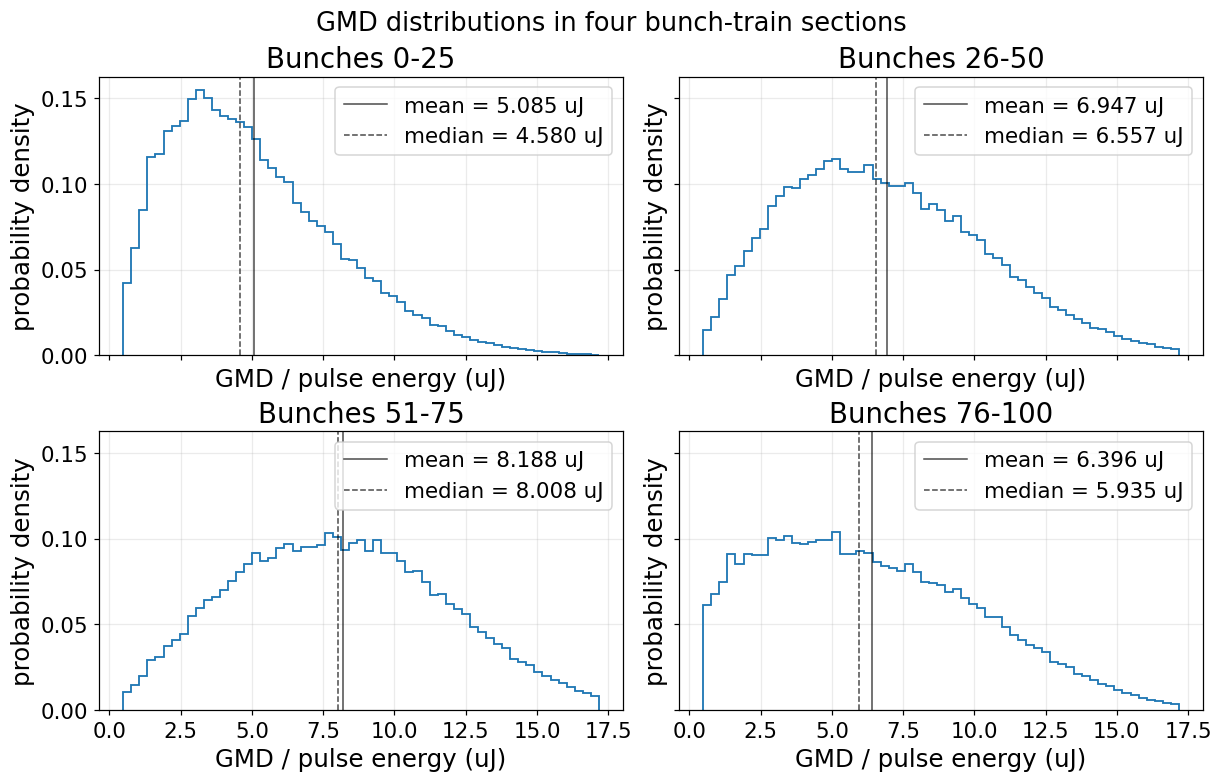

In [38]:
# --- Split the bunch train into four sections and compare GMD distributions ---

N_BUNCH_SECTIONS = 4

BUNCH_SECTIONS = [np.asarray(idx, dtype=int) for idx in np.array_split(np.arange(bunch.size), N_BUNCH_SECTIONS)]
BUNCH_SECTION_LABELS = [f"{bunch[idx[0]]}-{bunch[idx[-1]]}" for idx in BUNCH_SECTIONS]

print("Bunch-train sections:")
for label, idx in zip(BUNCH_SECTION_LABELS, BUNCH_SECTIONS):
    print(f"  {label}: {idx.size} bunch slots")


# Use common GMD bins so the four distributions can be compared directly.
gmd_kept = bunch_diag["gmd_kept"]
finite_gmd = gmd_kept[np.isfinite(gmd_kept)]

gmd_plot_min, gmd_plot_max = np.nanpercentile(finite_gmd, [0.5, 99.5])
gmd_edges = np.linspace(gmd_plot_min, gmd_plot_max, 60)

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True, constrained_layout=True)

for ax, idx, label in zip(axes.ravel(), BUNCH_SECTIONS, BUNCH_SECTION_LABELS):
    values = gmd_kept[:, idx].ravel()
    values = values[np.isfinite(values)]

    mean_gmd = np.mean(values)
    median_gmd = np.median(values)

    ax.hist(values, bins=gmd_edges, density=True, histtype="step", lw=1.2)
    ax.axvline(mean_gmd, color="k", lw=1.0, alpha=0.7, label=f"mean = {mean_gmd:.3f} uJ")
    ax.axvline(median_gmd, color="k", lw=1.0, ls="--", alpha=0.7, label=f"median = {median_gmd:.3f} uJ")

    ax.set_title(f"Bunches {label}")
    ax.set_xlabel("GMD / pulse energy (uJ)")
    ax.set_ylabel("probability density")
    ax.grid(alpha=0.25)
    ax.legend()

fig.suptitle("GMD distributions in four bunch-train sections")

plt.show()

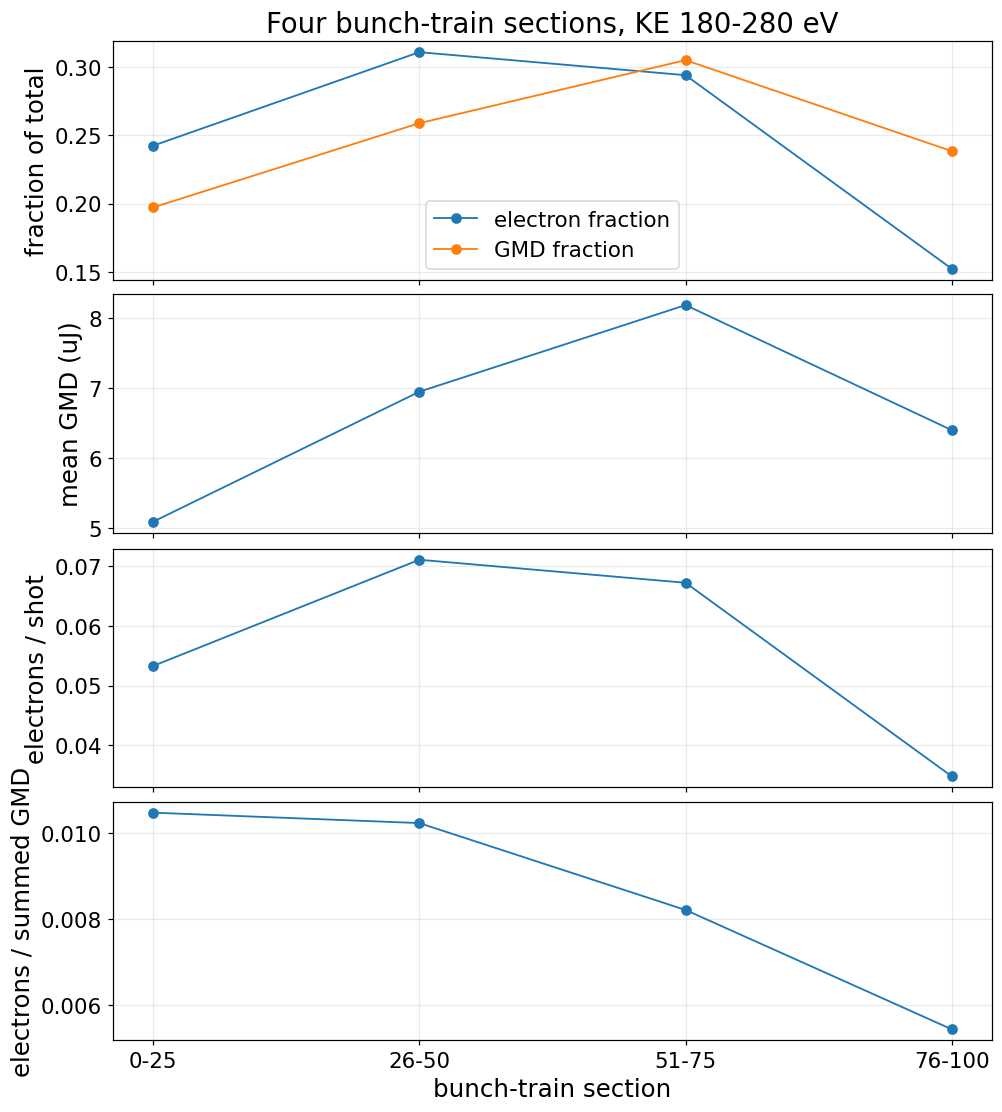


KE 180-280 eV
 section    shots     mean GMD      e/shot      e/GMD    e fraction   GMD fraction   filled slots
     0-25    851344      5.08524    0.05328     0.01048      0.24249        0.19719       0.00000
    26-50    818600      6.94711    0.07110     0.01024      0.31115        0.25903       0.00000
    51-75    818600      8.18794    0.06724     0.00821      0.29426        0.30529       0.00000
   76-100    818600      6.39640    0.03476     0.00543      0.15211        0.23849       0.00000


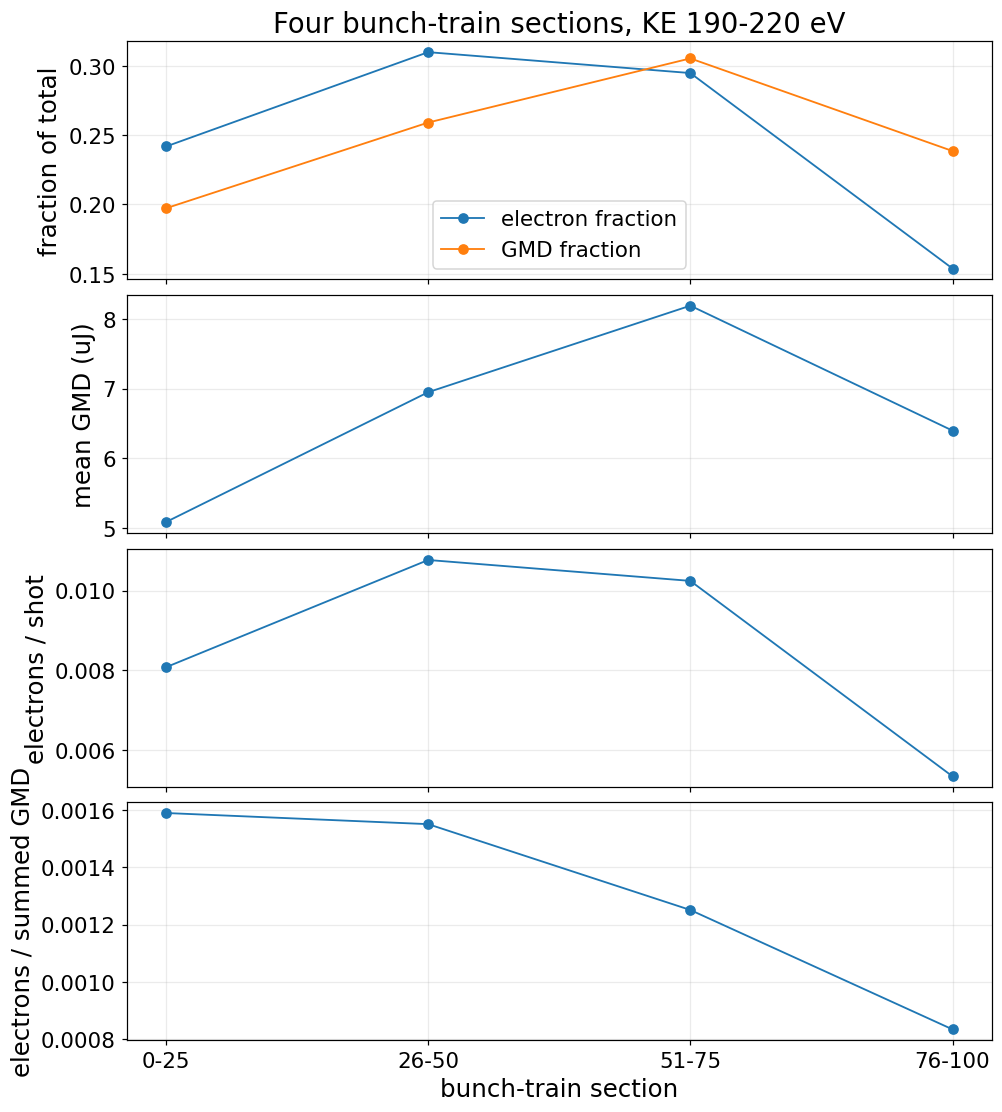


KE 190-220 eV
 section    shots     mean GMD      e/shot      e/GMD    e fraction   GMD fraction   filled slots
     0-25    851344      5.08524    0.00808     0.00159      0.24175        0.19719       0.00000
    26-50    818600      6.94711    0.01077     0.00155      0.30980        0.25903       0.00000
    51-75    818600      8.18794    0.01024     0.00125      0.29472        0.30529       0.00000
   76-100    818600      6.39640    0.00534     0.00084      0.15372        0.23849       0.00000


In [39]:
# --- Integrated electron response in the four bunch-train sections ---

def aggregate_bunch_section_stats(stats, idx):
    shots = np.nansum(stats["shots"][idx])
    sum_gmd = np.nansum(stats["sum_gmd"][idx])
    electrons = np.nansum(stats["electrons"][idx])
    slot_filled = np.nansum(stats["slot_filled"][idx])

    with np.errstate(invalid="ignore", divide="ignore"):
        mean_gmd = sum_gmd / shots
        electrons_per_shot = electrons / shots
        electrons_per_gmd = electrons / sum_gmd
        slot_filled_frac = slot_filled / shots

    return {
        "shots": shots,
        "sum_gmd": sum_gmd,
        "electrons": electrons,
        "mean_gmd": mean_gmd,
        "electrons_per_shot": electrons_per_shot,
        "electrons_per_gmd": electrons_per_gmd,
        "slot_filled_frac": slot_filled_frac,
    }


for ke_range in KE_RANGES:
    stats = bunch_diag["stats"]["all"][ke_range]

    section_stats = [aggregate_bunch_section_stats(stats, idx) for idx in BUNCH_SECTIONS]
    section_electrons = np.array([x["electrons"] for x in section_stats], dtype=float)
    section_gmd = np.array([x["sum_gmd"] for x in section_stats], dtype=float)

    electron_fraction = section_electrons / np.sum(section_electrons)
    gmd_fraction = section_gmd / np.sum(section_gmd)

    mean_gmd = np.array([x["mean_gmd"] for x in section_stats])
    electrons_per_shot = np.array([x["electrons_per_shot"] for x in section_stats])
    electrons_per_gmd = np.array([x["electrons_per_gmd"] for x in section_stats])

    x = np.arange(N_BUNCH_SECTIONS)

    fig, axes = plt.subplots(4, 1, figsize=(9, 10), sharex=True, constrained_layout=True)

    axes[0].plot(x, electron_fraction, "o-", lw=1.2, label="electron fraction")
    axes[0].plot(x, gmd_fraction, "o-", lw=1.2, label="GMD fraction")
    axes[0].set_ylabel("fraction of total")
    axes[0].set_title(f"Four bunch-train sections, KE {ke_range[0]}-{ke_range[1]} eV")
    axes[0].grid(alpha=0.25)
    axes[0].legend()

    axes[1].plot(x, mean_gmd, "o-", lw=1.2)
    axes[1].set_ylabel("mean GMD (uJ)")
    axes[1].grid(alpha=0.25)

    axes[2].plot(x, electrons_per_shot, "o-", lw=1.2)
    axes[2].set_ylabel("electrons / shot")
    axes[2].grid(alpha=0.25)

    axes[3].plot(x, electrons_per_gmd, "o-", lw=1.2)
    axes[3].set_ylabel("electrons / summed GMD")
    axes[3].set_xlabel("bunch-train section")
    axes[3].grid(alpha=0.25)

    axes[3].set_xticks(x)
    axes[3].set_xticklabels(BUNCH_SECTION_LABELS)

    plt.show()

    print(f"\nKE {ke_range[0]}-{ke_range[1]} eV")
    print(" section    shots     mean GMD      e/shot      e/GMD    e fraction   GMD fraction   filled slots")

    for label, st, e_frac, g_frac in zip(BUNCH_SECTION_LABELS, section_stats, electron_fraction, gmd_fraction):
        print(f" {label:>8s}  {st['shots']:8.0f}  {st['mean_gmd']:11.5f}  {st['electrons_per_shot']:9.5f}  {st['electrons_per_gmd']:10.5f}  {e_frac:11.5f}  {g_frac:13.5f}  {st['slot_filled_frac']:12.5f}")

Using GMD ranges:
  1-2 uJ: (1.0, 2.0)
  3-4 uJ: (3.0, 4.0)
  5-6 uJ: (5.0, 6.0)
  6-8 uJ: (6.0, 8.0)
  8-12 uJ: (8.0, 12.0)


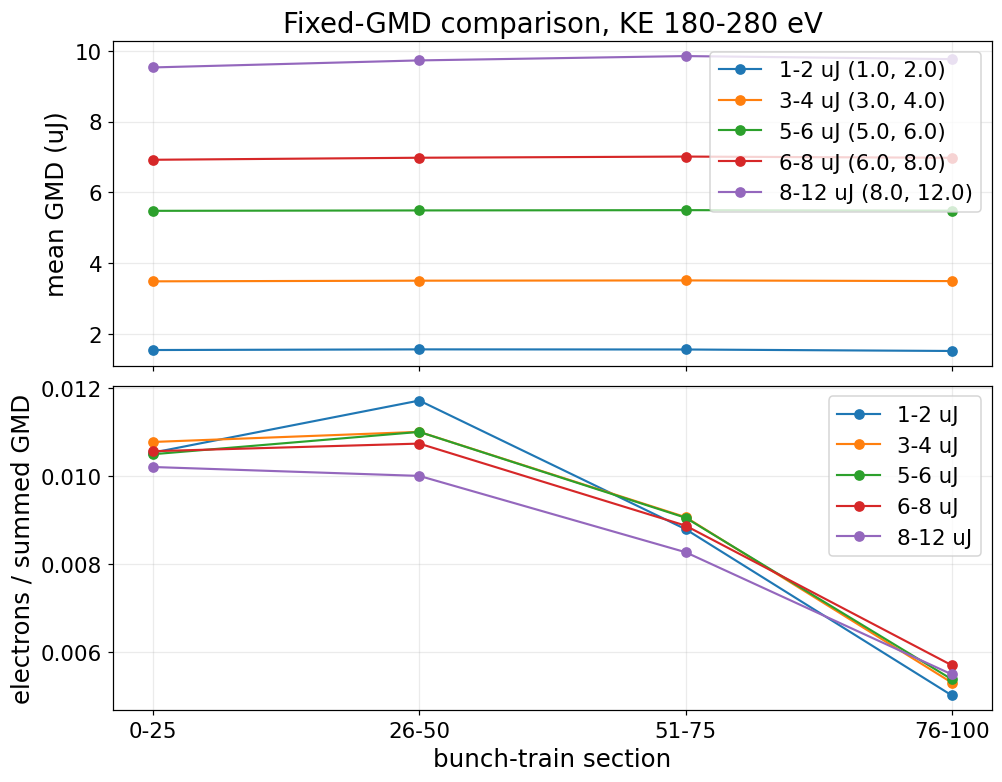


Section values
 section   GMD group      mean GMD      e/GMD       shots
     0-25       1-2 uJ      1.54599      0.01054      89821
     0-25       3-4 uJ      3.48715      0.01078     125267
     0-25       5-6 uJ      5.47960      0.01050      97410
     0-25       6-8 uJ      6.92253      0.01057     141168
     0-25      8-12 uJ      9.53217      0.01021     118884
    26-50       1-2 uJ      1.56435      0.01172      35944
    26-50       3-4 uJ      3.50580      0.01101      78307
    26-50       5-6 uJ      5.49106      0.01101      88983
    26-50       6-8 uJ      6.98003      0.01074     166347
    26-50      8-12 uJ      9.73074      0.01001     219148
    51-75       1-2 uJ      1.56099      0.00879      21782
    51-75       3-4 uJ      3.51304      0.00907      51326
    51-75       5-6 uJ      5.49897      0.00905      72550
    51-75       6-8 uJ      7.01314      0.00887     156840
    51-75      8-12 uJ      9.85307      0.00827     276869
   76-100       1-2 uJ    

In [40]:
# --- Presentation view: bunch-position effect at fixed GMD ranges ---

PLOT_KE_RANGE = (180, 280)
GMD_LABELS = [label for label in bunch_diag["gmd_ranges"] if label != "all"]

print("Using GMD ranges:")
for label in GMD_LABELS:
    print(f"  {label}: {bunch_diag['gmd_ranges'][label]}")

def section_values(stats):
    mean_gmd, e_per_gmd, shots = [], [], []
    for idx in BUNCH_SECTIONS:
        n_shots = np.sum(stats["shots"][idx])
        sum_gmd = np.sum(stats["sum_gmd"][idx])
        electrons = np.sum(stats["electrons"][idx])
        mean_gmd.append(sum_gmd / n_shots)
        e_per_gmd.append(electrons / sum_gmd)
        shots.append(n_shots)
    return np.asarray(mean_gmd), np.asarray(e_per_gmd), np.asarray(shots)

group_values = {}
for label in GMD_LABELS:
    group_values[label] = section_values(bunch_diag["stats"][label][PLOT_KE_RANGE])

x = np.arange(len(BUNCH_SECTIONS))
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True, constrained_layout=True)

for label in GMD_LABELS:
    mean_gmd, e_gmd, _ = group_values[label]
    axes[0].plot(x, mean_gmd, "o-", lw=1.4, label=f"{label} {bunch_diag['gmd_ranges'][label]}")
    axes[1].plot(x, e_gmd, "o-", lw=1.4, label=label)

axes[0].set_ylabel("mean GMD (uJ)")
axes[0].set_title(f"Fixed-GMD comparison, KE {PLOT_KE_RANGE[0]}-{PLOT_KE_RANGE[1]} eV")
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].set_ylabel("electrons / summed GMD")
axes[1].set_xlabel("bunch-train section")
axes[1].set_xticks(x)
axes[1].set_xticklabels(BUNCH_SECTION_LABELS)
axes[1].grid(alpha=0.25)
axes[1].legend()
plt.show()

print("\nSection values")
print(" section   GMD group      mean GMD      e/GMD       shots")
for section_i, section_label in enumerate(BUNCH_SECTION_LABELS):
    for label in GMD_LABELS:
        mean_gmd, e_gmd, shots = group_values[label]
        print(f" {section_label:>8s}   {label:>10s}   {mean_gmd[section_i]:10.5f}   {e_gmd[section_i]:10.5f}   {shots[section_i]:8.0f}")

Using trim_start = 3, trim_end = 3
Bunch sections: 0-25, 26-50, 51-75, 76-100


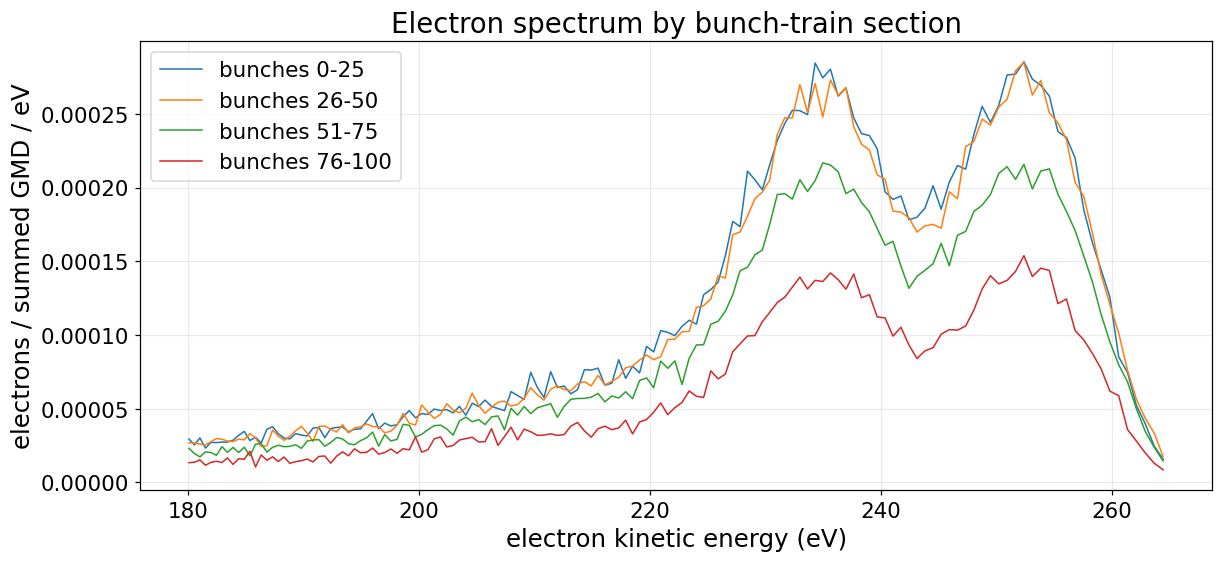

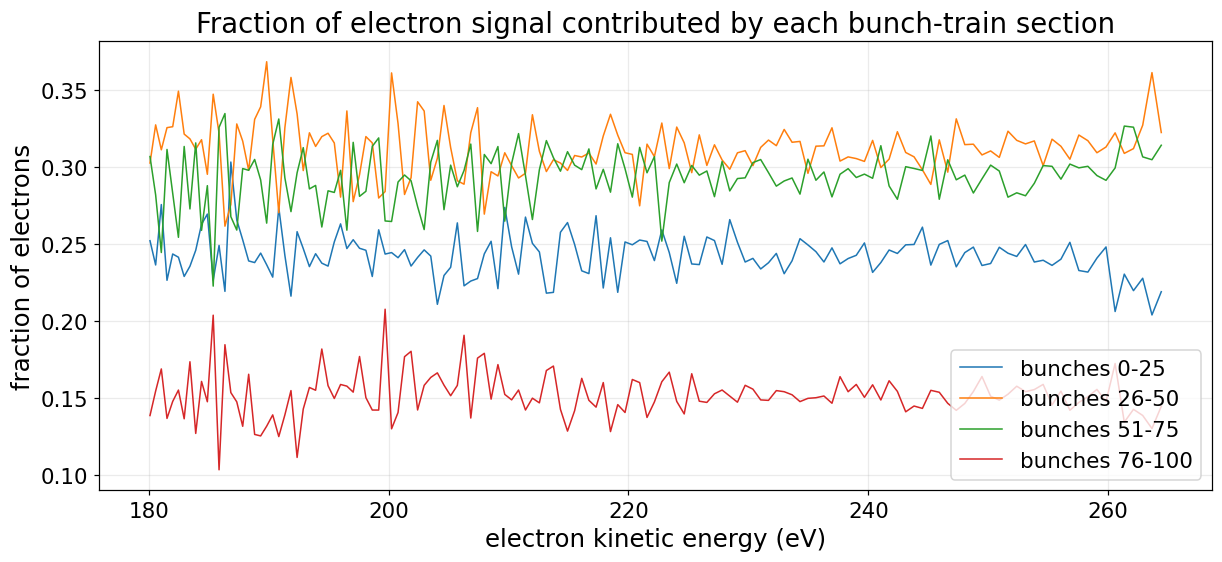

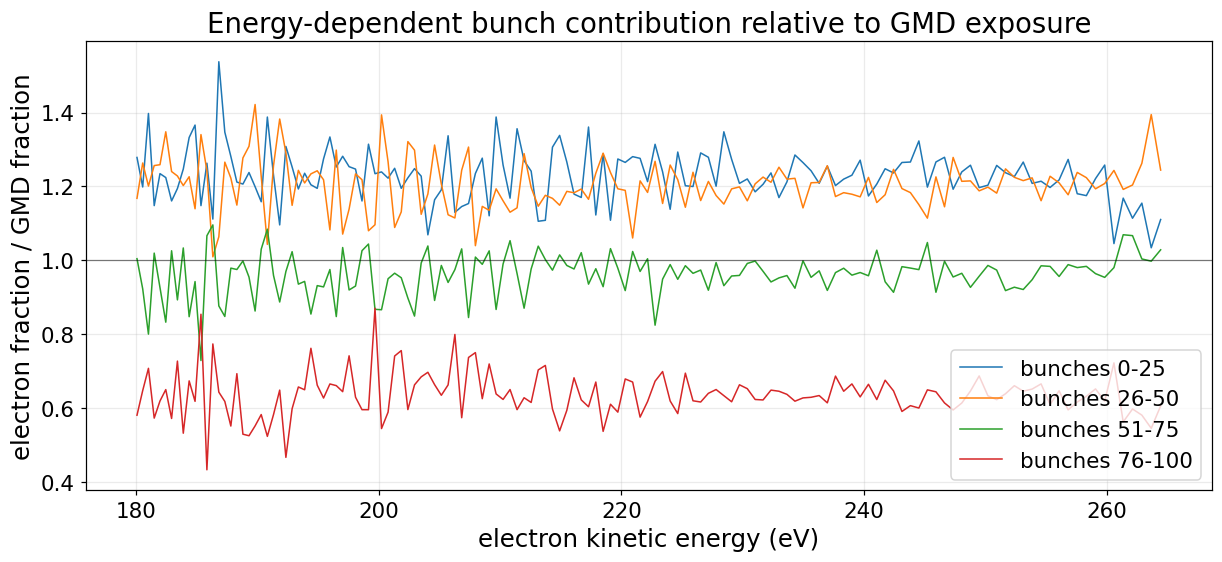


Four-section exposure summary
 section      shots        summed GMD     mean GMD     GMD fraction
     0-25      851344     4.32929e+06      5.08524        0.19719
    26-50      818600     5.68691e+06      6.94711        0.25903
    51-75      818600     6.70265e+06      8.18794        0.30529
   76-100      818600     5.23609e+06       6.3964        0.23849


In [41]:
# --- Energy-resolved electron contribution for four bunch-train sections, native TOF grid ---

import numpy as np
import matplotlib.pyplot as plt
import h5py

SECTION_SPECTRUM_KE_RANGE = (180.0, 265.0)
SECTION_TOF_RANGE = (800, 1200)
SECTION_CHUNK_TRAINS = 1000

# Recover the same trim settings used for the bunch-position analysis.
if "TRIM_START_BUNCH" in globals() and "TRIM_END_BUNCH" in globals():
    trim_start_bunch = int(TRIM_START_BUNCH)
    trim_end_bunch = int(TRIM_END_BUNCH)
elif "diag_agg" in globals():
    metadata = diag_agg.get("metadata", diag_agg) if isinstance(diag_agg, dict) else getattr(diag_agg, "metadata", {})
    trim_start_bunch = int(metadata.get("trim_start", 0) or 0) if hasattr(metadata, "get") else 0
    trim_end_bunch = int(metadata.get("trim_end", 0) or 0) if hasattr(metadata, "get") else 0
else:
    trim_start_bunch = 0
    trim_end_bunch = 0
    print("WARNING: trim metadata not found; using trim_start = trim_end = 0.")

print(f"Using trim_start = {trim_start_bunch}, trim_end = {trim_end_bunch}")

def _keep_mask_for_bunch_checks(f, trim_start=0, trim_end=0):
    if "between_tdc_files" not in f:
        return np.ones(f["gmd"].shape[0], dtype=bool)
    btf = f["between_tdc_files"][:].astype(bool)
    good_pos = np.where(~btf)[0]
    good_pos = good_pos[trim_start:-trim_end] if trim_end > 0 else good_pos[trim_start:]
    keep = np.zeros(btf.shape[0], dtype=bool)
    keep[good_pos] = True
    return keep

# Split the bunch train into four sections.
n_bunch = bunch_diag["bunch"].size
N_BUNCH_SECTIONS = 4
BUNCH_SECTIONS = [np.asarray(idx, dtype=int) for idx in np.array_split(np.arange(n_bunch), N_BUNCH_SECTIONS)]
BUNCH_SECTION_LABELS = [f"{idx[0]}-{idx[-1]}" for idx in BUNCH_SECTIONS]
print("Bunch sections:", ", ".join(BUNCH_SECTION_LABELS))

# Native TOF bins. No interpolation and no uniform KE rebinning.
tof_edges_native = np.arange(SECTION_TOF_RANGE[0], SECTION_TOF_RANGE[1] + 1, 1.0)
tof_centres_native = 0.5 * (tof_edges_native[:-1] + tof_edges_native[1:])
ke_edges_native = tof_to_ke(tof_edges_native)
ke_centres_native = tof_to_ke(tof_centres_native)
ke_width_native = np.abs(np.diff(ke_edges_native))

section_counts = np.zeros((N_BUNCH_SECTIONS, tof_centres_native.size), dtype=float)
section_sum_gmd = np.zeros(N_BUNCH_SECTIONS, dtype=float)
section_shots = np.zeros(N_BUNCH_SECTIONS, dtype=np.int64)

# Read raw hits while preserving bunch position.
with h5py.File(source_h5, "r") as f:
    keep = _keep_mask_for_bunch_checks(f, trim_start=trim_start_bunch, trim_end=trim_end_bunch)
    n_trains = f["gmd"].shape[0]

    for start in range(0, n_trains, SECTION_CHUNK_TRAINS):
        stop = min(start + SECTION_CHUNK_TRAINS, n_trains)
        row_keep = keep[start:stop]
        if not row_keep.any():
            continue

        gmd = f["gmd"][start:stop][row_keep]
        tofs = f["tofs_e"][start:stop][row_keep]

        for i_section, idx in enumerate(BUNCH_SECTIONS):
            gmd_section = gmd[:, idx]
            valid_shot = np.isfinite(gmd_section)
            tofs_section = tofs[:, idx, :]
            valid_hit = (tofs_section > 0) & np.isfinite(tofs_section) & valid_shot[..., None]

            counts, _ = np.histogram(tofs_section[valid_hit], bins=tof_edges_native)
            section_counts[i_section] += counts
            section_sum_gmd[i_section] += np.nansum(np.where(valid_shot, gmd_section, 0.0))
            section_shots[i_section] += np.count_nonzero(valid_shot)

# Restrict to the requested KE region.
ke_mask = np.isfinite(ke_centres_native) & np.isfinite(ke_width_native) & (ke_width_native > 0)
ke_mask &= (ke_centres_native >= SECTION_SPECTRUM_KE_RANGE[0]) & (ke_centres_native <= SECTION_SPECTRUM_KE_RANGE[1])

ke_plot = ke_centres_native[ke_mask]
ke_width_plot = ke_width_native[ke_mask]
counts_plot = section_counts[:, ke_mask]

# tof_to_ke reverses the axis, so sort by increasing KE.
order = np.argsort(ke_plot)
ke_plot = ke_plot[order]
ke_width_plot = ke_width_plot[order]
counts_plot = counts_plot[:, order]

# GMD-normalised spectral density. Divide by unequal native KE-bin width.
with np.errstate(invalid="ignore", divide="ignore"):
    section_spectra_per_gmd_ev = counts_plot / section_sum_gmd[:, None] / ke_width_plot[None, :]

fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
for label, spectrum in zip(BUNCH_SECTION_LABELS, section_spectra_per_gmd_ev):
    ax.plot(ke_plot, spectrum, lw=1.0, label=f"bunches {label}")
ax.set_xlabel("electron kinetic energy (eV)")
ax.set_ylabel("electrons / summed GMD / eV")
ax.set_title("Electron spectrum by bunch-train section")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

# Fraction of electron signal at each native KE bin from each section.
total_counts_by_energy = np.sum(counts_plot, axis=0)
good_energy = total_counts_by_energy > 0

with np.errstate(invalid="ignore", divide="ignore"):
    section_electron_fraction = counts_plot / total_counts_by_energy[None, :]

fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
for label, fraction in zip(BUNCH_SECTION_LABELS, section_electron_fraction):
    ax.plot(ke_plot[good_energy], fraction[good_energy], lw=1.0, label=f"bunches {label}")
ax.set_xlabel("electron kinetic energy (eV)")
ax.set_ylabel("fraction of electrons")
ax.set_title("Fraction of electron signal contributed by each bunch-train section")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

# Contribution relative to each section's fraction of total GMD.
gmd_fraction_by_section = section_sum_gmd / np.sum(section_sum_gmd)

with np.errstate(invalid="ignore", divide="ignore"):
    contribution_relative_to_gmd = section_electron_fraction / gmd_fraction_by_section[:, None]

fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
for label, relative_contribution in zip(BUNCH_SECTION_LABELS, contribution_relative_to_gmd):
    ax.plot(ke_plot[good_energy], relative_contribution[good_energy], lw=1.0, label=f"bunches {label}")
ax.axhline(1.0, color="k", lw=0.8, alpha=0.5)
ax.set_xlabel("electron kinetic energy (eV)")
ax.set_ylabel("electron fraction / GMD fraction")
ax.set_title("Energy-dependent bunch contribution relative to GMD exposure")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

print("\nFour-section exposure summary")
print(" section      shots        summed GMD     mean GMD     GMD fraction")
for label, shots, sum_gmd, gmd_frac in zip(BUNCH_SECTION_LABELS, section_shots, section_sum_gmd, gmd_fraction_by_section):
    mean_gmd = sum_gmd / shots
    print(f" {label:>8s}  {shots:10d}  {sum_gmd:14.6g}  {mean_gmd:11.6g}  {gmd_frac:13.5f}")

In [42]:
print("source_h5:", source_h5)
print("bunch_diag kept trains:", bunch_diag["gmd_kept"].shape[0])
print("current section trains, section 0:", section_shots[0] / len(BUNCH_SECTIONS[0]))
print("current section trains, section 1:", section_shots[1] / len(BUNCH_SECTIONS[1]))
print("trim:", trim_start_bunch, trim_end_bunch)

source_h5: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_274.0eV.h5
bunch_diag kept trains: 32788
current section trains, section 0: 32744.0
current section trains, section 1: 32744.0
trim: 3 3
